In [1]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "mushrooms.csv"

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "uciml/mushroom-classification",
  file_path,
)

print("First 5 records:")
print(df.head())

Using Colab cache for faster access to the 'mushroom-classification' dataset.
First 5 records:
  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type

In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['class'])
y = df['class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train distribution:\n{y_train.value_counts(normalize=True)}")
print(f"y_test distribution:\n{y_test.value_counts(normalize=True)}")

X_train shape: (6499, 22)
X_test shape: (1625, 22)
y_train distribution:
class
e    0.517926
p    0.482074
Name: proportion, dtype: float64
y_test distribution:
class
e    0.518154
p    0.481846
Name: proportion, dtype: float64


In [3]:
display(X_train)

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
5249,f,y,y,f,f,f,c,b,g,e,...,k,p,b,p,w,o,l,h,y,g
5781,x,s,p,t,n,f,c,b,e,e,...,s,e,w,p,w,t,e,w,c,w
7586,b,s,g,f,n,f,w,b,w,e,...,s,w,w,p,w,t,p,w,s,g
6181,f,s,n,f,s,f,c,n,b,t,...,k,p,w,p,w,o,e,w,v,d
7338,k,y,n,f,f,f,c,n,b,t,...,k,p,p,p,w,o,e,w,v,p
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6150,x,s,n,f,s,f,c,n,b,t,...,s,p,p,p,w,o,e,w,v,d
5386,x,y,n,f,n,f,w,n,w,e,...,f,w,n,p,w,o,e,w,v,l
1357,f,f,w,f,n,f,w,b,p,t,...,s,w,w,p,w,o,e,k,a,g
2977,x,f,g,t,n,f,c,b,w,t,...,s,g,p,p,w,o,p,n,y,d


In [4]:
display(y_train)

,class
5249,p
5781,e
7586,e
6181,p
7338,p
...,...
6150,p
5386,e
1357,e
2977,e


In [5]:
p_1 = sum([1 if i == "e" else 0 for i in y_train])/len(y_train)
p_0 = sum([1 if i == "p" else 0 for i in y_train])/len(y_train)

print(f"Edible (p_1): {p_1}")
print(f"Poisonous (p_0): {p_0}")
print(p_1+p_0)

Edible (p_1): 0.5179258347438067
Poisonous (p_0): 0.4820741652561933
1.0


In [10]:
classes = y_train.unique()
n_features = len(X_train.columns)
class_counts = {}
values = {}
for j in classes:
  class_counts[j]=sum([1 if i == j else 0 for i in y_train])

for i in X_train.columns:
  values[i] = list(X_train[i].unique())

print(classes)
print(n_features)
print(class_counts)
print(values)

['p' 'e']
22
{'p': 3133, 'e': 3366}
{'cap-shape': ['f', 'x', 'b', 'k', 's', 'c'], 'cap-surface': ['y', 's', 'f', 'g'], 'cap-color': ['y', 'p', 'g', 'n', 'e', 'w', 'c', 'b', 'r', 'u'], 'bruises': ['f', 't'], 'odor': ['f', 'n', 's', 'l', 'y', 'a', 'c', 'p', 'm'], 'gill-attachment': ['f', 'a'], 'gill-spacing': ['c', 'w'], 'gill-size': ['b', 'n'], 'gill-color': ['g', 'e', 'w', 'b', 'p', 'h', 'n', 'y', 'r', 'u', 'k', 'o'], 'stalk-shape': ['e', 't'], 'stalk-root': ['b', '?', 'r', 'e', 'c'], 'stalk-surface-above-ring': ['k', 's', 'f', 'y'], 'stalk-surface-below-ring': ['k', 's', 'y', 'f'], 'stalk-color-above-ring': ['p', 'e', 'w', 'g', 'n', 'b', 'o', 'c', 'y'], 'stalk-color-below-ring': ['b', 'w', 'p', 'n', 'o', 'g', 'e', 'c', 'y'], 'veil-type': ['p'], 'veil-color': ['w', 'n', 'o', 'y'], 'ring-number': ['o', 't', 'n'], 'ring-type': ['l', 'e', 'p', 'n', 'f'], 'spore-print-color': ['h', 'w', 'n', 'k', 'o', 'u', 'r', 'y', 'b'], 'population': ['y', 'c', 's', 'v', 'n', 'a'], 'habitat': ['g', 'w', 

In [18]:
# X_train = X_train.values.tolist()
# y_train = y_train.tolist() 
values = [set(v) for v in values.values()]

In [19]:
from collections import Counter

counts = {}

for c in classes:
    counts[c] = [Counter() for j in range(n_features) ] 

for row, label in zip(X_train, y_train):
    for j, v in enumerate(row):
        counts[label][j][v] += 1

def likelihood(c, j, v):
    numerator   = counts[c][j][v] + 1
    denominator = class_counts[c] + len(values[j])
    return numerator / denominator

In [20]:
for c in classes:
    for j in range(n_features):
        total = sum(counts[c][j].values())
        if total != class_counts[c]:
            print("MISMATCH", c, j, total, class_counts[c])

print("check 1 done")

check 1 done


In [21]:
for c in classes:
    for j in range(n_features):
        total = sum(likelihood(c, j, v) for v in values[j])
        if abs(total - 1.0) > 1e-9:
            print("NOT 1.0:", c, j, total)

print("check 2 done")

check 2 done


In [22]:
print(len(values))    # should be 22
print(values[4])      # should be the odor values

22
{'m', 'c', 'f', 'a', 's', 'y', 'n', 'l', 'p'}


In [26]:
import math

n_train = len(y_train)
priors = {c: class_counts[c] / n_train for c in classes}

def predict_one(row):
    best_class = None
    best_score = float("-inf")
    for c in classes:
        score = math.log(priors[c])
        for j, v in enumerate(row):
            score += math.log(likelihood(c,j,v))
        if score > best_score:
            best_score = score
            best_class = c
    return best_class

In [28]:
X_test = X_test.values.tolist()
y_test = y_test.tolist()

In [29]:
y_pred = [predict_one(row) for row in X_test]

In [32]:
acc = sum([1 if y_pred[i]==y_test[i] else 0 for i in range(len(y_pred))])/len(y_pred)
print(acc)

0.9458461538461539


In [33]:
TP = FP = TN = FN = 0

for true, pred in zip(y_test, y_pred):
    if true == 'p' and pred == 'p':
        TP += 1
    elif true == 'p' and pred == 'e':
        FN += 1
    elif true == 'e' and pred == 'p':
        FP += 1
    else:
        TN += 1

print("            Pred p   Pred e")
print(f"Actual p    {TP:6d}   {FN:6d}")
print(f"Actual e    {FP:6d}   {TN:6d}")

            Pred p   Pred e
Actual p       702       81
Actual e         7      835


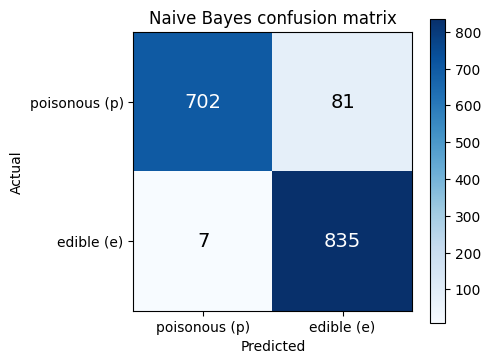

In [34]:
import numpy as np
import matplotlib.pyplot as plt

cm = np.array([[TP, FN],
               [FP, TN]])
labels = ['poisonous (p)', 'edible (e)']

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap='Blues')

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Naive Bayes confusion matrix')

# write the number in each cell
for i in range(2):
    for j in range(2):
        color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        ax.text(j, i, cm[i, j], ha='center', va='center', color=color, fontsize=14)

fig.colorbar(im)
plt.tight_layout()
plt.show()